# Liver Cirrhosis Survival Prediction
## Notebook 02 — Preprocess & Encode

**Loads from:** `data/train.csv` · `data/test.csv`  
**Saves to:** `processed/X_train.csv` · `processed/y_train.csv` · `processed/X_test.csv` · `processed/encoders.pkl`

**What this notebook does:**
1. Mounts Google Drive and sets working directory
2. Combines train + test for consistent preprocessing
3. Drops columns that cause leakage or carry no signal
4. Engineers Age from days → years
5. Caps outliers (Winsorize) without removing sick patients
6. Encodes all categorical variables
7. Builds correlation matrix → selects top features
8. Drops highly correlated features
9. Splits back into train / test and saves all outputs

---
> **Notebook dependencies:** Requires `data/train.csv` and `data/test.csv`  
> Run Notebook 01 first if you haven't — it confirms data quality.  
> All outputs saved to `processed/` folder for Notebook 03.

### Cell 2.0 — Mount Google Drive & set working directory

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.chdir('/content/drive/MyDrive/Maria_Sagwa/Cirrhosis_Project')

# Confirm location
print("Working directory:", os.getcwd())
print("Files found:", os.listdir())


Mounted at /content/drive
Working directory: /content/drive/MyDrive/Maria_Sagwa/Cirrhosis_Project
Files found: ['test.csv', 'train.csv', 'processed', 'outputs', 'notebook_03_train_evaluate.ipynb', 'Liver_Cirrhosis_Prediction notebook3.ipynb', 'notebook_01_load_explore.ipynb', 'notebook_02_preprocess_encode.ipynb', 'Liver_Cirrhosis_Prediction_notebook2_fixed.ipynb', 'Liver_Cirrhosis_Prediction notebook1.ipynb', 'Liver_Cirrhosis_Prediction notebook2.ipynb']


### Cell 2.1 — Imports

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

# Create processed/ folder if it doesn't exist
os.makedirs('processed', exist_ok=True)
os.makedirs('outputs',   exist_ok=True)

print("Libraries loaded ✓")
print("Folders ready   ✓")


Libraries loaded ✓
Folders ready   ✓


### Cell 2.2 — Load datasets

In [15]:
train = pd.read_csv('/content/drive/MyDrive/Maria_Sagwa/Cirrhosis_Project/train.csv')
test  = pd.read_csv('/content/drive/MyDrive/Maria_Sagwa/Cirrhosis_Project/test.csv')

print("=" * 65)
print("2.2  DATASETS LOADED")
print("=" * 65)
print(f"  Train : {train.shape[0]:,} rows × {train.shape[1]} columns")
print(f"  Test  : {test.shape[0]:,} rows × {test.shape[1]} columns")
print(f"\n  Train columns: {train.columns.tolist()}")
print(f"\n  Test columns : {test.columns.tolist()}")


2.2  DATASETS LOADED
  Train : 7,905 rows × 20 columns
  Test  : 5,271 rows × 19 columns

  Train columns: ['id', 'N_Days', 'Drug', 'Age', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin', 'Stage', 'Status']

  Test columns : ['id', 'N_Days', 'Drug', 'Age', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin', 'Stage']


### Cell 2.3 — Combine train + test for consistent preprocessing

We combine both sets before preprocessing so that encoding and scaling  
are applied identically to both. A `_split` tag keeps track of which  
rows are train and which are test so we can separate them again later.

In [16]:
train['_split'] = 'train'
test['_split']  = 'test'

# test.csv has no Status column — add NaN placeholder before concat
# so the combined DataFrame has a consistent Status column
if 'Status' not in test.columns:
    test['Status'] = np.nan

combined = pd.concat([train, test], ignore_index=True)


print("=" * 65)
print("2.3  COMBINED DATASET")
print("=" * 65)
print(f"  Combined : {combined.shape[0]:,} rows × {combined.shape[1]} columns")
print(f"  Train    : {(combined['_split'] == 'train').sum():,} rows")
print(f"  Test     : {(combined['_split'] == 'test').sum():,} rows")
print(f"\n  Status nulls (should equal test rows): {combined['Status'].isna().sum()}")


2.3  COMBINED DATASET
  Combined : 13,176 rows × 21 columns
  Train    : 7,905 rows
  Test     : 5,271 rows

  Status nulls (should equal test rows): 5271


In [17]:
print(combined.shape)
print(combined['_split'].value_counts())
print(combined['Status'].value_counts(dropna=False))
print(combined.head(3)[['_split', 'Status']])

(13176, 21)
_split
train    7905
test     5271
Name: count, dtype: int64
Status
NaN    5271
C      4965
D      2665
CL      275
Name: count, dtype: int64
  _split Status
0  train      D
1  train      C
2  train      D


### Cell 2.4 — Drop columns: N_Days, Drug, id

| Column | Reason for dropping |
|--------|-------------------|
| `id` | Row identifier — no predictive value |
| `N_Days` | Study follow-up duration — **data leakage**. A real patient has no N_Days at diagnosis time. Including it artificially inflates accuracy. |
| `Drug` | Random trial assignment (D-penicillamine vs Placebo). Correlation with Status = **0.018** — effectively zero signal. |


In [18]:
DROP_COLS = ['id', 'N_Days', 'Drug']
combined.drop(columns=DROP_COLS, inplace=True)

print("=" * 65)
print("2.4  DROPPED COLUMNS")
print("=" * 65)
for col in DROP_COLS:
    print(f"  ✗ {col}")
print(f"\n  Remaining columns ({len(combined.columns)}):")
print(f"  {combined.columns.tolist()}")


2.4  DROPPED COLUMNS
  ✗ id
  ✗ N_Days
  ✗ Drug

  Remaining columns (18):
  ['Age', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin', 'Stage', 'Status', '_split']


### Cell 2.5 — Feature engineering: Age days → years

Age is stored in days in the dataset. Converting to years makes it  
interpretable and clinically meaningful for both the model and the web app.


In [19]:
combined['Age'] = (combined['Age'] / 365.25).round(0)

print("=" * 65)
print("2.5  AGE CONVERSION  (days → years)")
print("=" * 65)
print(combined['Age'].describe().round(1))
print(f"\n  Range: {combined['Age'].min()} – {combined['Age'].max()} years")


2.5  AGE CONVERSION  (days → years)
count    13176.0
mean        50.4
std         10.0
min         26.0
25%         43.0
50%         51.0
75%         57.0
max         78.0
Name: Age, dtype: float64

  Range: 26.0 – 78.0 years


### Cell 2.6 — Outlier capping (Winsorize 1st–99th percentile)

We **cap** rather than **drop** extreme values because:
- High Bilirubin, high Copper, high Prothrombin are clinically meaningful —
  they mark the sickest patients
- Dropping those rows removes exactly the cases the model most needs to learn
- Winsorizing pulls extreme values to the 1st/99th percentile boundary  
  so they stay in the dataset but don't distort the model

**Important:** Percentile boundaries are computed on **training rows only**  
then applied to the full combined set — this prevents test data statistics  
leaking into the preprocessing.


In [20]:
LAB_COLS = [
    'Bilirubin', 'Cholesterol', 'Albumin', 'Copper',
    'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin'
]

train_mask = combined['_split'] == 'train'

print("=" * 65)
print("2.6  OUTLIER CAPPING  (Winsorize 1st–99th percentile)")
print("=" * 65)
print(f"  {'Column':15}  {'Lower cap':>10}  {'Upper cap':>10}  {'Values affected':>16}")
print(f"  {'-'*15}  {'-'*10}  {'-'*10}  {'-'*16}")

for col in LAB_COLS:
    lo = combined.loc[train_mask, col].quantile(0.01)
    hi = combined.loc[train_mask, col].quantile(0.99)
    n_affected = ((combined[col] < lo) | (combined[col] > hi)).sum()
    combined[col] = combined[col].clip(lower=lo, upper=hi)
    print(f"  {col:15}  {lo:>10.2f}  {hi:>10.2f}  {n_affected:>16}")


2.6  OUTLIER CAPPING  (Winsorize 1st–99th percentile)
  Column            Lower cap   Upper cap   Values affected
  ---------------  ----------  ----------  ----------------
  Bilirubin              0.40       20.00               212
  Cholesterol          151.00     1276.00               247
  Albumin                2.43        4.30               160
  Copper                10.00      412.00               234
  Alk_Phos             378.48    11036.55               262
  SGOT                  45.00      272.29               273
  Tryglicerides         50.00      309.00               252
  Platelets             80.00      493.00               223
  Prothrombin            9.50       13.00               208


### Cell 2.7 — Verify outlier capping (visualisation)

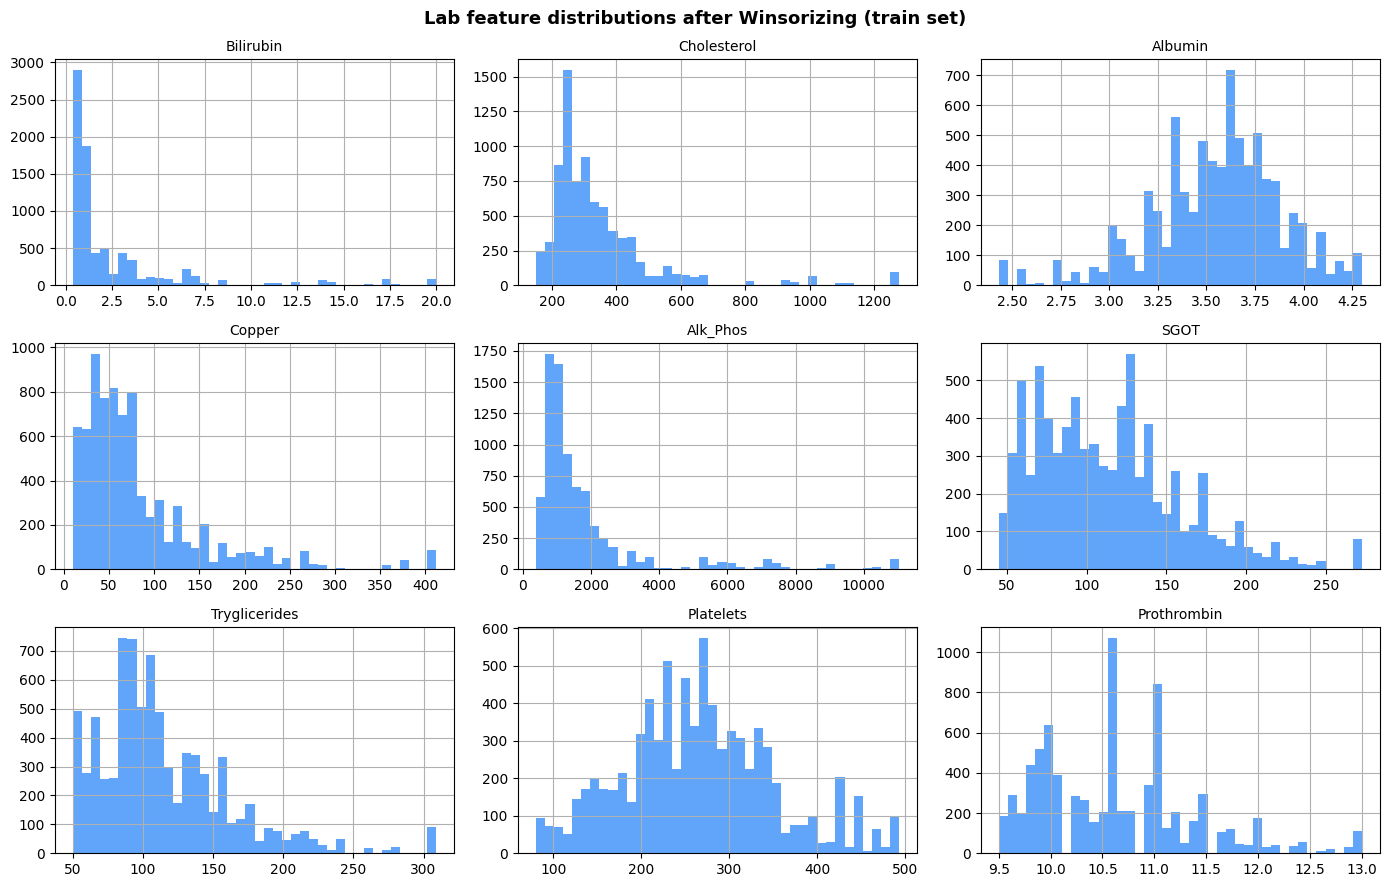

Saved → outputs/02_outlier_verification.png


In [21]:
train_mask = combined['_split'] == 'train'
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
fig.suptitle('Lab feature distributions after Winsorizing (train set)',
             fontsize=13, fontweight='bold')

for ax, col in zip(axes.flatten(), LAB_COLS):
    combined.loc[train_mask, col].hist(bins=40, ax=ax, color='#60a5fa', edgecolor='none')
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('')

plt.tight_layout()
plt.savefig('outputs/02_outlier_verification.png', dpi=130, bbox_inches='tight')
plt.show()
print("Saved → outputs/02_outlier_verification.png")


### Cell 2.8 — Encode binary categorical columns

Binary columns (only 2 unique values) are label-encoded to 0 / 1.  
We check whether encoding has already been applied before running  
so this cell is safe to re-run without causing errors.

| Column | Encoding |
|--------|----------|
| Sex | M → 0, F → 1 |
| Ascites | N → 0, Y → 1 |
| Hepatomegaly | N → 0, Y → 1 |
| Spiders | N → 0, Y → 1 |


In [22]:
binary_maps = {
    'Sex':          {'M': 0, 'F': 1},
    'Ascites':      {'N': 0, 'Y': 1},
    'Hepatomegaly': {'N': 0, 'Y': 1},
    'Spiders':      {'N': 0, 'Y': 1},
}

# Store encoders so Flask can use identical encoding for new patients
encoders = {}

print("=" * 65)
print("2.8  BINARY COLUMN ENCODING")
print("=" * 65)

for col, mapping in binary_maps.items():
    sample_val = combined[col].dropna().iloc[0]
    if isinstance(sample_val, str):
        combined[col] = combined[col].map(mapping)
        encoders[col] = mapping
        print(f"  {col:15} → encoded   {mapping}")
    else:
        print(f"  {col:15} → already encoded, skipped")


2.8  BINARY COLUMN ENCODING
  Sex             → encoded   {'M': 0, 'F': 1}
  Ascites         → encoded   {'N': 0, 'Y': 1}
  Hepatomegaly    → encoded   {'N': 0, 'Y': 1}
  Spiders         → encoded   {'N': 0, 'Y': 1}


### Cell 2.9 — Encode Edema (one-hot)

Edema has 3 categories — it cannot be label-encoded because  
that would imply a false ordering (N < S < Y).  
One-hot encoding creates a separate binary column for each category.  
We drop the first (N = no edema) to avoid multicollinearity.

| Value | Meaning |
|-------|---------|
| N | No edema |
| S | Edema present, no diuretics used |
| Y | Edema present despite diuretics |

In [23]:
print("=" * 65)
print("2.9  EDEMA ONE-HOT ENCODING")
print("=" * 65)

if 'Edema' in combined.columns:
    edema_dummies = pd.get_dummies(combined['Edema'], prefix='Edema',
                                   drop_first=True, dtype=int)
    combined = pd.concat([combined.drop('Edema', axis=1), edema_dummies], axis=1)
    encoders['Edema'] = 'one-hot: N=baseline, S=Edema_S, Y=Edema_Y'
    print(f"  Edema → one-hot encoded")
    print(f"  New columns: {[c for c in combined.columns if 'Edema' in c]}")
    print(f"  N (no edema) is the baseline — dropped to avoid multicollinearity")
else:
    print("  Edema already encoded, skipped")

2.9  EDEMA ONE-HOT ENCODING
  Edema → one-hot encoded
  New columns: ['Edema_S', 'Edema_Y']
  N (no edema) is the baseline — dropped to avoid multicollinearity


### Cell 2.10 — Encode Status (target column)

Status is our prediction target. We encode it to integers:

| Status | Meaning | Encoded |
|--------|---------|---------|
| C | Alive / censored | 0 |
| CL | Liver transplant | 1 |
| D | Deceased | 2 |

Test rows have NaN for Status (we're predicting those) —  
they will stay NaN and be excluded from training.

In [24]:
print("=" * 65)
print("2.10  STATUS AND STAGE ENCODING")
print("=" * 65)

status_map = {'C': 0, 'CL': 1, 'D': 2}

# Status is a string in train rows and NaN in test rows
# .map() handles NaN automatically — NaN stays NaN after mapping
if combined['Status'].dtype == object:
    combined['Status'] = combined['Status'].map(status_map)
    encoders['Status'] = status_map
    print(f"  Status → encoded  {status_map}")
    print(f"  (test rows remain NaN — this is correct, we predict those)")
else:
    print("  Status already encoded, skipped")

combined['Stage'] = combined['Stage'].astype(int)
print(f"  Stage  → cast to int")

print(f"\n  Status distribution (train rows only):")
train_mask = combined['_split'] == 'train'
print(combined.loc[train_mask, 'Status'].value_counts().sort_index()
      .rename({0:'C — alive', 1:'CL — transplant', 2:'D — deceased'}))


2.10  STATUS AND STAGE ENCODING
  Status → encoded  {'C': 0, 'CL': 1, 'D': 2}
  (test rows remain NaN — this is correct, we predict those)
  Stage  → cast to int

  Status distribution (train rows only):
Status
C — alive          4965
CL — transplant     275
D — deceased       2665
Name: count, dtype: int64


### Cell 2.11 — Verify encoding

In [25]:
print("=" * 65)
print("2.11  VERIFY ENCODING")
print("=" * 65)
print(combined.dtypes)
print(f"\nFirst 3 rows:")
display(combined.head(3))


2.11  VERIFY ENCODING
Age              float64
Sex                int64
Ascites            int64
Hepatomegaly       int64
Spiders            int64
Bilirubin        float64
Cholesterol      float64
Albumin          float64
Copper           float64
Alk_Phos         float64
SGOT             float64
Tryglicerides    float64
Platelets        float64
Prothrombin      float64
Stage              int64
Status           float64
_split            object
Edema_S            int64
Edema_Y            int64
dtype: object

First 3 rows:


,Age,Sex,Ascites,Hepatomegaly,Spiders,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status,_split,Edema_S,Edema_Y
0,59.0,0,0,0,0,2.3,316.0,3.35,172.0,1601.0,179.80,63.0,394.0,9.7,3,2.0,train,0,0
1,53.0,1,0,0,0,0.9,364.0,3.54,63.0,1440.0,134.85,88.0,361.0,11.0,3,0.0,train,0,0
2,38.0,1,0,1,1,3.3,299.0,3.55,131.0,1029.0,119.35,50.0,199.0,11.7,4,2.0,train,0,1


In [26]:
train_enc = combined[combined['_split'] == 'train'].copy()
print("Status dtype:", train_enc['Status'].dtype)
print("Status nulls:", train_enc['Status'].isna().sum())
print("Status unique:", train_enc['Status'].unique())

Status dtype: float64
Status nulls: 0
Status unique: [2. 0. 1.]


### Cell 2.12 — Correlation matrix & feature selection

We calculate the absolute correlation of each feature with Status  
on the training rows only (test rows have no Status values).  
This tells us which features are most predictive of survival.


In [27]:
# Use only train rows and drop any rows where Status is NaN
train_enc = combined[combined['_split'] == 'train'].copy()
train_enc = train_enc.dropna(subset=['Status'])   # removes any remaining NaN rows

# Only numeric columns — excludes _split (object) and any residual strings
feat_cols = [
    c for c in train_enc.columns
    if c not in ['Status', '_split']
    and pd.api.types.is_numeric_dtype(train_enc[c])
]

corr_target = (
    train_enc[feat_cols + ['Status']]
    .corr()['Status']
    .drop('Status')
    .dropna()             # drop any NaN correlations
    .abs()
    .sort_values(ascending=False)
)

print("=" * 65)
print("2.12  FEATURE CORRELATION WITH STATUS")
print("=" * 65)

for feat, val in corr_target.items():
    bar = '█' * int(val * 40)
    print(f"  {feat:15}  {val:.3f}  {bar}")


2.12  FEATURE CORRELATION WITH STATUS
  Bilirubin        0.443  █████████████████
  Prothrombin      0.399  ███████████████
  Copper           0.397  ███████████████
  Hepatomegaly     0.396  ███████████████
  Stage            0.347  █████████████
  SGOT             0.329  █████████████
  Spiders          0.324  ████████████
  Albumin          0.296  ███████████
  Edema_Y          0.282  ███████████
  Ascites          0.274  ██████████
  Tryglicerides    0.199  ███████
  Cholesterol      0.192  ███████
  Platelets        0.177  ███████
  Edema_S          0.172  ██████
  Age              0.168  ██████
  Alk_Phos         0.159  ██████
  Sex              0.131  █████


### Cell 2.13 — Inter-feature correlation heatmap

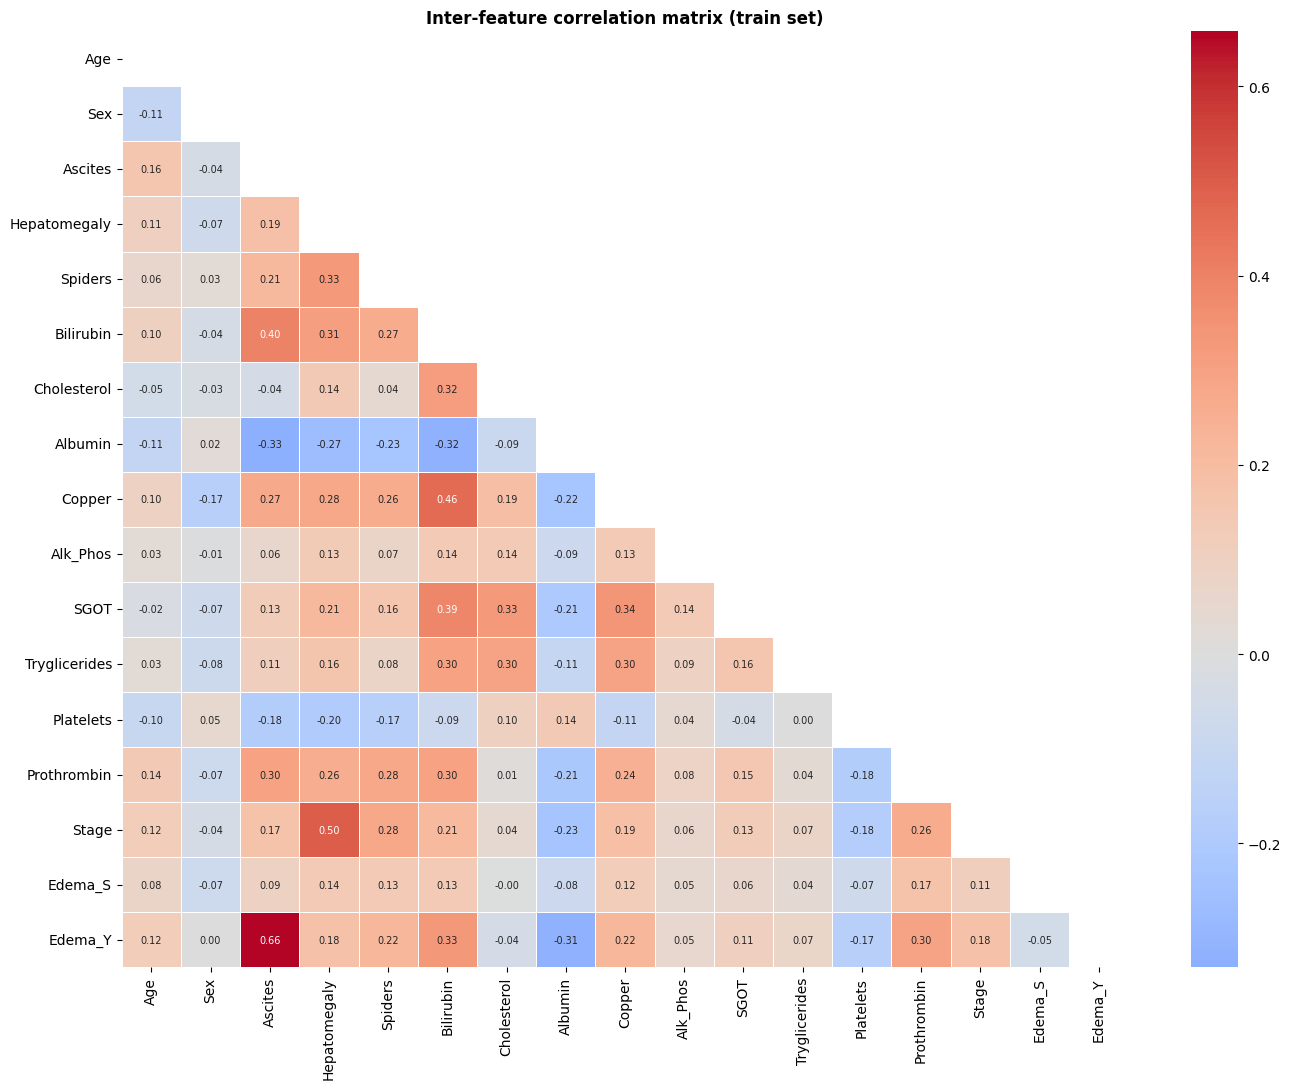

Saved → outputs/02_correlation_matrix.png


In [28]:
train_enc = combined[combined['_split'] == 'train'].copy()
feat_cols = [
    c for c in train_enc.columns
    if c not in ['Status', '_split']
    and pd.api.types.is_numeric_dtype(train_enc[c])
]

corr_matrix = train_enc[feat_cols].corr()

plt.figure(figsize=(14, 11))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask,
    annot=True, fmt='.2f',
    cmap='coolwarm', center=0,
    linewidths=0.4,
    annot_kws={'size': 7}
)
plt.title('Inter-feature correlation matrix (train set)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/02_correlation_matrix.png', dpi=130, bbox_inches='tight')
plt.show()
print("Saved → outputs/02_correlation_matrix.png")


### Cell 2.14 — Drop highly correlated feature pairs (threshold > 0.80)

When two features are highly correlated with each other, they carry  
redundant information. We keep the one with the higher correlation  
to Status and drop the other.

In [29]:
THRESHOLD = 0.80
train_enc = combined[combined['_split'] == 'train'].copy()
feat_cols = [
    c for c in train_enc.columns
    if c not in ['Status', '_split']
    and pd.api.types.is_numeric_dtype(train_enc[c])
]
corr_matrix = train_enc[feat_cols].corr().abs()

print("=" * 65)
print(f"2.14  HIGH INTER-FEATURE CORRELATIONS  (threshold > {THRESHOLD})")
print("=" * 65)

to_drop = set()
found   = False

for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        val   = corr_matrix.iloc[i, j]
        col_a = corr_matrix.columns[i]
        col_b = corr_matrix.columns[j]
        if val > THRESHOLD:
            found = True
            drop_col = col_a if corr_target[col_a] < corr_target[col_b] else col_b
            to_drop.add(drop_col)
            print(f"  {col_a} <-> {col_b} : {val:.3f}  → dropping {drop_col}")

if not found:
    print("  No pairs above threshold ✓  No features dropped.")

if to_drop:
    combined.drop(columns=list(to_drop), inplace=True)
    print(f"\n  Dropped: {list(to_drop)}")

2.14  HIGH INTER-FEATURE CORRELATIONS  (threshold > 0.8)
  No pairs above threshold ✓  No features dropped.


### Cell 2.15 — Select top N features

We automatically select the top 7 features by absolute correlation  
with Status. This is data-driven — no hardcoding.  
The number 7 balances model performance vs. keeping the lab tech  
entry form in Flask manageable.


In [30]:
# Recompute correlation after any dropped columns
train_enc = combined[combined['_split'] == 'train'].copy()
train_enc = train_enc.dropna(subset=['Status'])

feat_cols = [
    c for c in train_enc.columns
    if c not in ['Status', '_split']
    and pd.api.types.is_numeric_dtype(train_enc[c])
]

corr_target = (
    train_enc[feat_cols + ['Status']]
    .corr()['Status']
    .drop('Status')
    .dropna()
    .abs()
    .sort_values(ascending=False)
)

TOP_N = 7
SELECTED_FEATURES = corr_target.head(TOP_N).index.tolist()

print("=" * 65)
print(f"2.15  SELECTED FEATURES  (top {TOP_N} by correlation with Status)")
print("=" * 65)
for i, feat in enumerate(SELECTED_FEATURES, 1):
    print(f"  {i}. {feat:15}  corr = {corr_target[feat]:.3f}")

print()



2.15  SELECTED FEATURES  (top 7 by correlation with Status)
  1. Bilirubin        corr = 0.443
  2. Prothrombin      corr = 0.399
  3. Copper           corr = 0.397
  4. Hepatomegaly     corr = 0.396
  5. Stage            corr = 0.347
  6. SGOT             corr = 0.329
  7. Spiders          corr = 0.324



### Cell 2.16 — Split back into train / test and save

We separate the combined dataset back into train and test,  
keep only the selected features, and save everything to `processed/`.  
Notebook 03 will load these files — it does not depend on this notebook being open.


In [31]:
train_final = combined[combined['_split'] == 'train'].copy()
test_final  = combined[combined['_split'] == 'test'].copy()

train_final.drop(columns=['_split'], inplace=True)
test_final.drop(columns=['_split', 'Status'], inplace=True)

X_train = train_final[SELECTED_FEATURES]
print(train_final['Status'].isna().sum())
print(train_final['Status'].unique())
y_train = train_final['Status'].dropna().astype(int)
X_test  = test_final[SELECTED_FEATURES]

print("=" * 65)
print("2.16  SPLIT BACK INTO TRAIN / TEST")
print("=" * 65)
print(f"  X_train : {X_train.shape}   features: {X_train.columns.tolist()}")
print(f"  y_train : {y_train.shape}")
print(f"  X_test  : {X_test.shape}")
print(f"\n  y_train distribution:")
for cls, name in [(0,'C — alive'), (1,'CL — transplant'), (2,'D — deceased')]:
    n = (y_train == cls).sum()
    print(f"    {name:22}  {n:5,}  ({n/len(y_train)*100:.1f}%)")

# Save
X_train.to_csv('processed/X_train.csv', index=False)
y_train.to_csv('processed/y_train.csv', index=False)
X_test.to_csv('processed/X_test.csv',   index=False)

# Save encoders (Flask will load these to preprocess new patient inputs)
joblib.dump(encoders, 'processed/encoders.pkl')

print(f"\n  Saved to processed/:")
print(f"  ✓ X_train.csv  ({X_train.shape[0]:,} rows × {X_train.shape[1]} cols)")
print(f"  ✓ y_train.csv  ({y_train.shape[0]:,} rows)")
print(f"  ✓ X_test.csv   ({X_test.shape[0]:,} rows × {X_test.shape[1]} cols)")
print(f"  ✓ encoders.pkl (binary maps + Edema encoding + Status map)")


0
[2. 0. 1.]
2.16  SPLIT BACK INTO TRAIN / TEST
  X_train : (7905, 7)   features: ['Bilirubin', 'Prothrombin', 'Copper', 'Hepatomegaly', 'Stage', 'SGOT', 'Spiders']
  y_train : (7905,)
  X_test  : (5271, 7)

  y_train distribution:
    C — alive               4,965  (62.8%)
    CL — transplant           275  (3.5%)
    D — deceased            2,665  (33.7%)

  Saved to processed/:
  ✓ X_train.csv  (7,905 rows × 7 cols)
  ✓ y_train.csv  (7,905 rows)
  ✓ X_test.csv   (5,271 rows × 7 cols)
  ✓ encoders.pkl (binary maps + Edema encoding + Status map)
